### 검색 Tool이 필요한 이유
- LLM의 파라미터에 담긴 지식은 최신 사실을 보장하지 않음
- 웹 검색 도구는 외부 자료를 가져오는 역할
- 검색 결과 자체가 틀리거나 악성 지시를 포함할 수 있으므로 신뢰할 수 있는 출처와 날짜를 확인

```
사용자 -> LLM -> 검색 필요? -> 아니오 -> 답변
                          -> 예 -> 검색 Tool -> 결과 확인 -> LLM -> 답변
```

# **1 Tavily**
AI 애플리케이션과 Agent가 웹에서 정보를 검색하고, 검색 결과의 제목/주소/본문 일부를 구조화된 데이터로 받도록 지원하는 검색 API 서비스

In [48]:
import os
from dotenv import load_dotenv

In [49]:
load_dotenv()
OPENAI_API_KEY = bool(os.getenv("OPENAI_API_KEY"))
TAVILY_API_KEY = bool(os.getenv("TAVILY_API_KEY"))
OPENAI_MODEL = bool(os.getenv("OPENAI_MODEL"))
print("OPENAI_API_KEY:", OPENAI_API_KEY, "| TAVILY_API_KEY:", TAVILY_API_KEY, "| OPENAI_MODEL:", OPENAI_MODEL)

OPENAI_API_KEY: True | TAVILY_API_KEY: True | OPENAI_MODEL: True


In [50]:
MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-6-luna")

In [51]:
from langchain_openai import ChatOpenAI

In [52]:
def make_llm():
    if not OPENAI_API_KEY:
        print("KEY ERROR")
        return None
    return ChatOpenAI(model=MODEL_NAME, reasoning_effort="none", timeout=30, max_retries=2, temperature=0)

In [53]:
llm = make_llm()

In [54]:
from tavily import TavilyClient   # pip install tavily

In [55]:
if TAVILY_API_KEY:
    tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))
    raw_search = tavily_client.search(query="랭그래프는 뭐야?", max_results=3)
    print("최상위 키:", list(raw_search.keys()))
    for idx, item in enumerate(raw_search.get("results", []), start=1):
        print(f"\n[{idx}] 제목:", item.get("title", ""))
        print("주소:", item.get("url", ""))
        print("요약:", str(item.get("content", ""))[:200])
else:
    print("KEY ERROR")

최상위 키: ['query', 'follow_up_questions', 'answer', 'images', 'results', 'response_time', 'request_id']

[1] 제목: LangGraph란 무엇이고 언제 쓰면 좋을까?
주소: https://velog.io/@ohback/LangGraph
요약: 여기서 등장하는 게 LangGraph다. 이름 그대로 그래프(노드/엣지)로 LLM 애플리케이션의 흐름을 설계한다.  
 LangChain이 블록(모델·프롬프트·툴)을 잘 조립하게 해주는 공구상자라면, LangGraph는 그 블록들이 언제, 어떤 조건으로, 어떤 상태를 들고 움직일지를 정밀하게 오케스트레이션하는 조감도 + 신호등에 가깝다.

  

## 그래

[2] 제목: 꿈 많은 사람의 이야기
주소: https://lsjsj92.tistory.com/696
요약: ## LangGraph란?

LangGraph는 LLM을 기반으로 상태를 유지하고(Stateful), 여러 단계에 걸쳐 작동하는(multi-step) 에이전트를 구축하기 위한 라이브러리입니다. 기존의 LangChain이 LLM과 외부 도구를 '연쇄적으로(chaining)' 연결하는 데 중점을 두었다면, LangGraph는 이러한 연결 구조를 순환(cycle

[3] 제목: 23화 22. LangGraph 기본과 응용
주소: https://brunch.co.kr/@aideveloper/132
요약: # 22. LangGraph 기본과 응용

LLM 시대, LangChain(랭체인)으로 배우는 AI 소프트웨어 개발

gaebalai-blog_ai-v3-1.jpg

## (1) LangGraph(랭그래프)란?

LangGraph(랭그래프)는 LangChain(랭체인)을 기반으로 하는 에이전트 프레임워크입니다. LangGraph(랭그래프)의 주요 특징은 복


In [56]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_tavily import TavilySearch

In [57]:
if llm is not None and TAVILY_API_KEY:
    search_tool = TavilySearch(max_results=3)
    search_llm = llm.bind_tools([search_tool])

    def search_agent_node(state: MessagesState):
        response = search_llm.invoke(state["messages"])
        return {"messages": [response]}

    search_builder = StateGraph(MessagesState)
    search_builder.add_node("agent", search_agent_node)
    search_builder.add_node("tools", ToolNode([search_tool]))
    search_builder.add_edge(START, "agent")
    search_builder.add_conditional_edges("agent", tools_condition)
    search_builder.add_edge("tools", "agent")
    search_graph = search_builder.compile()
    result = search_graph.invoke(
        {"messages": [{"role": "user", "content": "LangGraph 최신 공식 문서를 찾아줘"}]},
        config = {"recursion_limit": 10}
    )
    for message in result["messages"]:
        print(type(message).__name__, str(message.content)[:500])
else:
    print("KEY ERROR")

HumanMessage LangGraph 최신 공식 문서를 찾아줘
AIMessage 
ToolMessage {"query": "LangGraph official documentation latest LangChain docs", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://docs.langchain.com/oss/python/langgraph/overview", "title": "LangGraph overview - Docs by LangChain", "content": "Trusted by companies shaping the future of agents—including Klarna, Uber, J.P. Morgan, and more—LangGraph is a low-level orchestration framework and runtime for building, managing, and deploying long-running, stateful agents. Lang
AIMessage LangGraph 최신 공식 문서는 LangChain 공식 문서 사이트에서 확인할 수 있습니다.

- **LangGraph 개요**  
  https://docs.langchain.com/oss/python/langgraph/overview  
  LangGraph의 핵심 개념, 사용 목적, LangChain과의 차이를 설명합니다.

- **LangGraph 공식 문서 홈**  
  https://docs.langchain.com/oss/python/langgraph  
  Python용 LangGraph 문서 전체 목차입니다.

- **LangGraph 시작하기**  
  https://docs.langchain.com/oss/python/langgraph/quickstart  
  간단한 그래프와 에이전트를 직접 만들어 보는 빠른 시작 가이드입니다.

-

# **2. Reflection vs Reflexion**
- Reflection(반성)은 작성한 초안을 스스로 검토하고 고치는 작업
- Reflexion(확장형 반성)은 여러 번의 시도에서 실패 원인과 피드백을 기억해 다음 시도 전략까지 바꾸는 접근

> 공통점은 둘 다 "자기 평가"가 항상 맞다는 뜻은 아님

- 구성 요소: 초안 생성 > 평가 > 피드백 > 수정 > 재평가
- 평가 기준: 사실 정확성, 근거, 형식, 독자 수준, 빠진 항목
- 종료 조건: 통과 기준 만족, 최대 시도 횟수, 비용 상한
- 흔한 오류: LLM이 점수만 매기고 수정 지시를 전달하지 않은 것

In [58]:
from typing import TypedDict, Literal

In [69]:
class ReviewState(TypedDict):
    topic: str       # 주제
    draft: str       # 초안
    feedback: str    # 검토 결과, 수정 의견
    approved: bool   # 초안의 통과 여부
    attempts: int    # 작성한 횟수

# 초안 작성 또는 수정
def write_draft(state: ReviewState):
    text = f"{state["topic"]}은 중요한 개념입니다."
    if state["attempts"] > 0:
        text += "예시: 사용자의 질문을 검색하고 근거를 붙여 답합니다."
    return {"draft": text, "attempts": state["attempts"] + 1}

# 초안의 통과 여부 판단
def review_draft(state: ReviewState):
    good = "예시:" in state["draft"]
    return {"approved": good, "feedback": "통과" if good else "구체적인 예시를 추가하세요"}

# 조건 함수: 다시 작성할지 종료할지 결정
def review_route(state: ReviewState) -> Literal["write", "finish"]:
    return "finish" if state["approved"] or state["attempts"] >= 3 else "write"


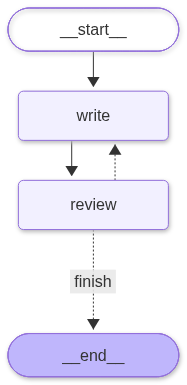

In [70]:
review_builder = StateGraph(ReviewState)
review_builder.add_node("write", write_draft)
review_builder.add_node("review", review_draft)
review_builder.add_edge(START, "write")
review_builder.add_edge("write", "review")
review_builder.add_conditional_edges("review", review_route, {"write": "write", "finish": END})
review_graph = review_builder.compile()
review_graph


In [71]:
review_result = review_graph.invoke({"topic": "RAG", "draft": "", "feedback": "", "approved": False, "attempts": 0})
print(review_result)

{'topic': 'RAG', 'draft': 'RAG은 중요한 개념입니다.예시: 사용자의 질문을 검색하고 근거를 붙여 답합니다.', 'feedback': '통과', 'approved': True, 'attempts': 2}


In [62]:
from pydantic import BaseModel, Field

In [63]:
class DraftGrade(BaseModel):
    score: int = Field(ge=0, le=5, description="정확성/구체성 기준 0~5점")
    strengths: str = Field(description="잘된 점")
    weaknesses: str = Field(description="부족한 점")
    revision_instrunction: str = Field(description="다음 수정 지시")

In [64]:
if llm is not None:
    grader = llm.with_structured_output(DraftGrade)
    sample_draft = "RAG는 문서를 찾아 답변을 만드는 방법입니다."
    grade = grader.invoke("다음 설명을 초보자용 교재 기분으로 평가하세요. 정확성, 예시, 주의사항을 확인하세요.\n" + sample_draft)
    print(grade.model_dump())

else:
    print("KEY ERROR")

{'score': 2, 'strengths': 'RAG를 문서 검색과 답변 생성의 결합으로 간단히 설명해 초보자가 핵심 개념에 접근하기 쉽습니다.', 'weaknesses': '‘문서를 찾아 답변을 만드는 방법’만으로는 RAG의 구성과 작동 과정이 지나치게 생략되어 있습니다. RAG는 일반적으로 질문과 관련된 외부 문서나 지식베이스를 검색(Retrieval)한 뒤, 검색 결과를 언어 모델의 입력 맥락으로 제공하여 답변을 생성(Generation)하는 방식입니다. 검색된 문서가 항상 정확하거나 충분한 것은 아니며, 검색 품질과 문서 최신성에 따라 답변의 정확도가 달라질 수 있다는 주의사항도 없습니다. 또한 간단한 예시가 없어 개념을 이해하기 어렵습니다.', 'revision_instrunction': '다음처럼 보완하세요: ‘RAG(Retrieval-Augmented Generation)는 사용자의 질문과 관련된 문서를 먼저 검색하고, 검색한 내용을 참고해 언어 모델이 답변을 생성하는 방법입니다. 예를 들어 사내 규정 문서를 검색한 뒤, “휴가 신청 방법은?”이라는 질문에 해당 규정의 내용을 근거로 답변할 수 있습니다. 다만 검색된 문서가 부정확하거나 최신이 아니면 답변도 틀릴 수 있으므로, 문서의 품질과 최신성을 확인해야 합니다.’'}


In [65]:
if llm is not None:
    original = "RAG는 검색을 합니다"
    feedback = "정의와 실제 예시, 한계점을 추가하세요"
    improved = llm.invoke(
        "당신은 AI 교육 교재 편집자입니다. 사실을 지어내지 마세요. \n"
        f"원문: {original}\n피드백: {feedback}\n 수정본만 작성하세요."
    )
    print(improved.content)

RAG(Retrieval-Augmented Generation)는 외부 문서나 데이터베이스에서 관련 정보를 검색한 뒤, 검색 결과를 참고해 답변을 생성하는 방식입니다. 예를 들어 사내 규정 문서에서 휴가 관련 내용을 검색하고, 그 결과를 바탕으로 직원의 질문에 답할 수 있습니다. 다만 검색된 정보의 정확성과 최신성에 따라 답변 품질이 달라지며, 관련 문서를 찾지 못하거나 검색 결과가 부정확하면 잘못된 답변이 생성될 수 있습니다.


# **3. RAG**
RAG(Retrieval_Augmunted Generation)는 생성형 AI가 외부 지식을 검색해 활용하는 방식으로,  
단순히 모델 파라미터에 저장된 정보만으로 답변하지 않고, 관련 문서를 검색(Retrieval)한 뒤 이를 입력 맥락에 포함시켜 답변을 생성합니다.  
이 방식은 모델이 최신 정보나 도메인 특화 지식을 활용할 수 있게 해주며, 환각(hallucination)을 줄이고 신뢰도를 높입니다.  
예를 들어 고객 지원, 법률 문서 검색, 논문 요약 등에서는 내부 데이터베이스에서 필요한 정보를 불러온 후 답변을 생성하는 형태로 적용됩니다.

### RAG 워크플로우
- 질문을 입력받은 뒤 쿼리를 벡터로 변환해 벡터DB에서 관련 문서를 검색하고 이를 컨텍스트로 합쳐 LLM이 답변을 생성하는 단일 경로의 직선형 파이프라인
- 검색과 생성이 고정된 순서로 연결되어 있어 빠르고 단순하며, FAQ나 사내 문서 QA처럼 명확한 질문/답변 작업에 적합

### 에이전틱 RAG 워크플로우
- 기본 RAG흐름 위에 에이전트의 자율성을 추가해 질문을 분석하고 필요할 때만 검색하거나 쿼리를 재작성해 여러 번 검색하며 검색 결과를 평가/반성 후 재시도하는 다단계 반복형 파이프라인입니다.  
LLM이 언제 검색할지, 어떤 도구를 쓸지, 어떻게 답변을 다듬을지까지 스스로 결정하므로 복잡한 리서치, 멀티홉 질의, 장기 과제에 더 강력합니다.
    - 단일 홉(Single-hop): 하나의 문서/사실만 찾아도 바로 답 가능

### RAG의 역할
- 검색(Retrieval): 질문과 관련된 자료를 찾음
- 증강(Augmentation): 검색 자료를 프롬프트의 근거로 제공
- 생성(Generation): 근거를 읽고 답변 작성

> RAG가 환각을 자동으로 없애지는 않음. 검색 실패, 오래된 문서, 잘못된 근거 연결, LLM의 근거 오독이 남음

In [67]:
from pathlib import Path
from langchain_community.document_loaders import PyPDFLoader

C:\Users\SHJ\AppData\Local\Temp\ipykernel_17376\1909073654.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [68]:
pdf_candidates = sorted(Path.cwd().glob("SPRi*.pdf"))
print("현재 폴더:", Path.cwd())
print("발견한 PDF:", [p.name for p in pdf_candidates])

현재 폴더: c:\SHJ\KDT\14_Agent
발견한 PDF: ['SPRi AI Brief 2026년 10월호(2026-10-09).pdf']


In [75]:
pdf_path = pdf_candidates[0]
pdf_pages = PyPDFLoader(str(pdf_path)).load()
print("읽은 PDF 페이지 수:", len(pdf_pages))
print("첫 페이지의 메타데이터:", pdf_pages[0].metadata)
print("PDF 5페이지 일부:", pdf_pages[4].page_content[:500])

Ignoring wrong pointing object 7 0 (offset 0)
Ignoring wrong pointing object 18 0 (offset 0)
Ignoring wrong pointing object 25 0 (offset 0)
Ignoring wrong pointing object 30 0 (offset 0)
Ignoring wrong pointing object 38 0 (offset 0)
Ignoring wrong pointing object 49 0 (offset 0)
Ignoring wrong pointing object 57 0 (offset 0)
Ignoring wrong pointing object 64 0 (offset 0)
Ignoring wrong pointing object 72 0 (offset 0)
Ignoring wrong pointing object 80 0 (offset 0)
Ignoring wrong pointing object 90 0 (offset 0)
Ignoring wrong pointing object 98 0 (offset 0)
Ignoring wrong pointing object 106 0 (offset 0)
Ignoring wrong pointing object 113 0 (offset 0)
Ignoring wrong pointing object 120 0 (offset 0)
Ignoring wrong pointing object 131 0 (offset 0)
Ignoring wrong pointing object 139 0 (offset 0)
Ignoring wrong pointing object 146 0 (offset 0)
Ignoring wrong pointing object 153 0 (offset 0)
Ignoring wrong pointing object 160 0 (offset 0)
Ignoring wrong pointing object 170 0 (offset 0)
Ignor

읽은 PDF 페이지 수: 28
첫 페이지의 메타데이터: {'producer': 'macOS 버전 26.6.2(빌드 25G83) Quartz PDFContext', 'creator': '한글', 'creationdate': "D:20261009073006Z00'00'", 'moddate': "D:20261009073006Z00'00'", 'title': '무제', 'source': 'c:\\SHJ\\KDT\\14_Agent\\SPRi AI Brief 2026년 10월호(2026-10-09).pdf', 'total_pages': 28, 'page': 0, 'page_label': '1'}
PDF 5페이지 일부: SPRi AI Brief
 2
0
2
6
년
  1
0
월
호
4
EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도
328)287
EU 「AI 법」의 투명성 의무가 2026년 8월 2일 적용 개시되었고, EU 집행위원회는 범용 AI 모델 
의무 준수 여부를 확인하기 위해 전 세계 30여 개 범용 AI 모델 제공 기업에 정보 요청 전달 
미국은 G20 혁신 장관회의에서 특정 기술만을 겨냥한 신규 규제를 지양하는 '캐롤라이나 원칙'을 제
시하였고, G20 회원국은 합의한 장관 성명에서 이 원칙을 참고해 각국 정책 체계를 수립하기로 함
EU, 투명성 의무 적용 개시하고, 범용 AI 모델 의무 집행 개시
유럽연합(EU)의 포괄적 AI 규제 법인 「AI 법」의 투명성 의무가 2026년 8월 2일부터 적용 개시
이에 따라 AI 시스템 제공자와 배포자는 사용자가 AI와 상호작용하고 있음을 고지하고, AI 생성 콘텐츠에 
기계 판독 가능한 표시를 제공하며, 딥페이크 등


- Chunk(청크): 긴 문서를 검색하기 쉬운 작은 조각으로 분할한 것. 너무 작으면 맥락이 끊기고 너무 크면 잡음이 늘어남
- Vector DB(벡터 DB): 임베딩을 저장하고 유사한 벡터를 검색하는 시스템.
- Retriever(검색기): 질문을 받아 관련 문서 목록을 반환하는 인터페이스
- Overlap(겹침): 문장 경계에서 정보가 끊기는 현상을 줄임. 저장량과 중복 결과를 늘림

In [77]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

In [78]:
# RecursiveCharacterTextSplitter: 문단, 줄바꿈, 공백 등을 우선 고려해 분할하는 도구
pdf_splitter = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=100)
pdf_chunks = pdf_splitter.split_documents(pdf_pages)
for i, doc in enumerate(pdf_chunks):
    doc.metadata["doc_id"] = f'SPRi-{i:04d}'
    doc.metadata["page_display"] = int(doc.metadata.get("page", 0)) + 1
print("페이지:", len(pdf_pages), "청크:", len(pdf_chunks))

페이지: 28 청크: 86


In [79]:
for doc in pdf_chunks[:2]:
    print("ID:", doc.metadata["doc_id"], "PDF 쪽:", doc.metadata["page_display"])
    print(repr(doc.page_content[:200]))

ID: SPRi-0000 PDF 쪽: 1
'10월호\nੋҕ\u0ad1\x01מ\u0891স\u0a44\x01୭न\x01زೱ'
ID: SPRi-0001 PDF 쪽: 2
'Ἂк\x0b\x13ዞம⸺⺟ ∙ 2026년 9월 AI 모델 현황 2\n⁋⑻\n･\nᓋ⁒\n∙ EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도 4\n∙미·중 정상, ‘초지능’ 대화와 소통 창구 구축 합의 5\n∙미국 의회, 잇단 AI 규제 발의에도 입법은 정체 6\n∙미국 사이버보안 합동 권고문, 대규모 지식 증류를 통한 모델 탈취 경고 7\n∙중국 최고인민법원, A'


### metadata를 보존하는 이유
- 검색 결과가 예를 들어 "EU AI 법의 투명성 의무"라고 말할 때 어느 페이지에서 나온 말인지 알아야 함
- doc_id는 검색 결과를 중복 제거하거나 평가할 때 사용하는 청크 ID
- page_display는 PDF 뷰어에서 볼 수 있는 1부터 시작하는 페이지 번호
    - 보고서 본문에 인쇄된 쪽수와 PDF 뷰어 쪽수는 표지/목차 때문에 다를 수 있음

- Vector Store: 데이터를 저장/검색하는 시스템
- BM25Retriever: 단어 기반 검색기
- Query: 검색할 질문/검색어
- Corpus: 검색 대상 문서 전체
- Candidate: 검색기가 찾아낸 문서

In [81]:
import re
from langchain_community.retrievers import BM25Retriever

In [83]:
def simple_tokens(text: str):
    return re.findall(r"[가-힣A-Za-z0-9]+", text.lower())

pdf_bm25 = BM25Retriever.from_documents(pdf_chunks, preprocess_func=simple_tokens)
pdf_bm25.k = 4    # 가져올 결과 개수토
pdf_hits = pdf_bm25.invoke("Muse 개인용 AI 에이전트 기능")
for rank, doc in enumerate(pdf_hits, start=1):
    print(f"{rank}위 | PDF {doc.metadata['page_display']}쪽 | {doc.metadata['doc_id']}")
    print(doc.page_content[:200].replace("\n", " "))

1위 | PDF 13쪽 | SPRi-0038
328)287 메타가 이메일이나 캘린더, 결제 등 일상적으로 사용하는 앱과 서비스를 연동해 다양한  업무를 수행하는 개인용 AI 에이전트 ‘Muse’ 출시 Muse는 출시 후 첫 12일간 미국·캐나다 iOS 다운로드 수가 ChatGPT
2위 | PDF 2쪽 | SPRi-0001
Ἂкዞம⸺⺟ ∙ 2026년 9월 AI 모델 현황 2 ⁋⑻ ･ ᓋ⁒ ∙ EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도 4 ∙미·중 정상, ‘초지능’ 대화와 소통 창구 구축 합의 5 ∙미국 의회, 잇단 AI 규제 발의에도 입법은 정체 6 ∙미국 사이버보안 합동 권고문, 대규모 지식 증류를 통한 모델 탈취 경고 7 ∙중국 최고인민법원, A
3위 | PDF 13쪽 | SPRi-0040
앱토피아(Apptopia)에 따르면 Muse는 출시 첫 12일간 미국·캐나다 iOS에서 180만 건이 다운로드 되어 ChatGPT(130만 건)를 앞섰으며, 같은 기간 전 세계 누적 설치 수는 280만 건을 기록 미국 매체 악시오스(Axios)에 따르면 최근 스타트업과 빅테크가 잇달아 개인용 에이전트 서비스를  출시하며 관련 시장이 활성화 비공개 베타
4위 | PDF 14쪽 | SPRi-0042
328)287 중국 스마트폰 제조사 오포와 비보, 아너가 각각 AI 에이전트에 앱과 개인정보, 기기 기능  접근 권한을 부여하는 신규 운영체제를 공개 3개 스마트폰 제조사가 발표한 신규


In [ ]:
# OpenAIEmbeddings: 임베딩 모델. 글자를 의미 비교에 쓸 숫자 배열로 바꿈. PDF 청크 전체를 임베딩하면 API 호출 비용이 많이 발생할 수 있음
# Chroma: 임베딩 벡터와 문서 정보를 저장하고 비슷한 벡터를 검색하는 데이터베이스

from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma

In [88]:
if OPENAI_API_KEY:
    pdf_embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")
    pdf_vectorsotre = Chroma.from_documents(documents=pdf_chunks, embedding=pdf_embedding_model, collection_name="spri_ai_bref_202610")

    # as_retriever(): 벡터 저장소를 retriever 방식으로 사용할 수 있게 바꿈
    pdf_vector_retriever = pdf_vectorsotre.as_retriever(search_kwargs = {"k": 4})
    pdf_vector_hits = pdf_vector_retriever.invoke("개인 비서가 이메일과 일정 관리를 돕는다는 내용")
    for doc in pdf_vector_hits:
        print(f"PDF {doc.metadata["page_display"]}쪽 | {doc.page_content[:120]}")
else:
    print("KEY ERROR")

PDF 14쪽 | 트에 앱과 개인정보, 기기 기능 접근 권한을 부여하며 AI를 운영체제에 심층 통합하는 단계에 진입
AI 모델이 복잡한 작업을 계획하고 조율하며 완수하도록 돕는 소프트웨어 계층인 ‘하네스(Harness)’를 
핵심 
PDF 14쪽 | 트에 앱과 개인정보, 기기 기능 접근 권한을 부여하며 AI를 운영체제에 심층 통합하는 단계에 진입
AI 모델이 복잡한 작업을 계획하고 조율하며 완수하도록 돕는 소프트웨어 계층인 ‘하네스(Harness)’를 
핵심 
PDF 13쪽 | SPRi AI Brief
 2
0
2
6
년
  1
0
월
호
12
메타, 개인용 AI 에이전트 ‘Muse’ 출시
328)287
메타가 이메일이나 캘린더, 결제 등 일상적으로 사용하는 앱과 서비스를 연동해 
PDF 13쪽 | SPRi AI Brief
 2
0
2
6
년
  1
0
월
호
12
메타, 개인용 AI 에이전트 ‘Muse’ 출시
328)287
메타가 이메일이나 캘린더, 결제 등 일상적으로 사용하는 앱과 서비스를 연동해 


### BM25와 벡터 Retriever를 비교
- BM25는 단어가 정확히 들어간 문서를 찾는 데 강함
- 벡터 검색은 다른 표현을 써도 관련 문서를 찾을 가능성이 높음
- 둘 다 틀린 문서를 가져올 수 있으므로 검색 결과를 직접 검토해야 함
- 검색된 4개 문서가 모두 답변에 필요한 근거인 것은 아님. Top-K는 개수 제한이지 정답 보장이 아님